# BLIP-2: Score leave-one-query-out ablation (LOQOA)

This CPU-only notebook analyzes saved predictions from `leave_one_query_out.ipynb`. It uses the same pinned official VQAv2 evaluator as `score_results.ipynb`, without loading BLIP-2, generating predictions, or reading COCO images. The original K=32 reference and all 32 K=31 omissions must belong to the same completed experiment.

For query $i\in\{0,\ldots,31\}$, define marginal importance (in percentage points) as

$$I_i=A_{32}-A_{-i}.$$

Positive importance means removing query $i$ lowered accuracy; negative importance means removal improved observed accuracy. This is conditional marginal importance, not an independent measure of query utility or an optimal-pruning ranking.

Run this notebook from the project root or `scripts/` after the inference notebook has finished. The 10-question smoke run verifies the pipeline; the 200-question pilot is exploratory; the 2,000-question main run supports the primary analysis. Keep the query-count scorer and its results separate.

In [1]:
from pathlib import Path
import copy
import hashlib
import io
import json
import os
import types
import urllib.request
from contextlib import redirect_stdout

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from filelock import FileLock
from IPython.display import display

STAGE = "main"  # "smoke" (10), "pilot" (200), or "main" (2000)
EXPERIMENT_DIR = None  # e.g. "results/leave_one_query_out/smoke-<signature>"
GPU_BACKEND = None  # None, "cuda", or "rocm"
BOOTSTRAP_REPLICATES = 2000
BOOTSTRAP_SEED = 425

STAGE_SIZES = {"smoke": 10, "pilot": 200, "main": 2000}
if STAGE not in STAGE_SIZES or GPU_BACKEND not in {None, "cuda", "rocm"}:
    raise ValueError("Invalid stage or GPU backend.")
if BOOTSTRAP_REPLICATES < 2:
    raise ValueError("At least two bootstrap replicates are required.")

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "scripts" else cwd
RESULTS_ROOT = PROJECT_ROOT / "results" / "leave_one_query_out"


def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def recorded_backend(exp):
    return exp.get("gpu_backend") or ("rocm" if exp.get("rocm_version") else
                                      "cuda" if exp.get("cuda_version") else "unknown")


if EXPERIMENT_DIR is None:
    candidates = []
    for path in sorted(RESULTS_ROOT.glob(f"{STAGE}-*/complete.json")):
        candidate = load_json(path.parent / "manifest.json")["experiment"]
        if (candidate.get("experiment_type") == "leave_one_query_out"
                and candidate["stage"] == STAGE
                and (GPU_BACKEND is None or recorded_backend(candidate) == GPU_BACKEND)):
            candidates.append((path.parent, candidate))
    if not candidates:
        raise FileNotFoundError(f"No completed LOQOA {STAGE} run found. Run leave_one_query_out.ipynb first.")
    if len(candidates) > 1:
        options = "\n".join(f"  {path} | {exp['gpu_name']} | {recorded_backend(exp)}" for path, exp in candidates)
        raise ValueError("Multiple runs match; set EXPERIMENT_DIR to one of:\n" + options)
    EXPERIMENT_DIR = candidates[0][0]

EXPERIMENT_DIR = (PROJECT_ROOT / Path(EXPERIMENT_DIR)).resolve()
manifest = load_json(EXPERIMENT_DIR / "manifest.json")
experiment = manifest["experiment"]
complete = load_json(EXPERIMENT_DIR / "complete.json")
expected_signature = hashlib.sha256(json.dumps(experiment, sort_keys=True).encode()).hexdigest()
if expected_signature != manifest["signature"] or complete["signature"] != expected_signature:
    raise ValueError("Manifest or completion signature does not match.")
if experiment.get("experiment_type") != "leave_one_query_out" or experiment["stage"] != STAGE:
    raise ValueError("Selected experiment is not a LOQOA run for the requested stage.")
backend = recorded_backend(experiment)
if GPU_BACKEND is not None and backend != GPU_BACKEND:
    raise ValueError("Selected experiment does not match GPU_BACKEND.")

question_ids = experiment["question_ids"]
conditions = experiment["conditions"]
if len(question_ids) != STAGE_SIZES[STAGE] or len(set(question_ids)) != len(question_ids):
    raise ValueError("Unexpected or duplicate question IDs.")
expected_names = {"k032", *(f"drop-query-{i:02d}" for i in range(32))}
if len(conditions) != 33 or {c["name"] for c in conditions} != expected_names:
    raise ValueError("Expected exactly the 33 LOQOA conditions.")
for c in conditions:
    removed = None if c["name"] == "k032" else int(c["name"].split("-")[-1])
    expected_indices = [i for i in range(32) if i != removed]
    if (c["removed_query"] != removed or c["k"] != len(expected_indices)
            or c["query_indices"] != expected_indices or c["seed"] is not None):
        raise ValueError(f"Unexpected retained query indices: {c['name']}")
if complete["condition_count"] != 33 or complete["questions_per_condition"] != len(question_ids):
    raise ValueError("Completion counts do not match the manifest.")
print(f"Scoring {STAGE}: {len(question_ids):,} questions × 33 conditions | {experiment['gpu_name']} ({backend})")
print(EXPERIMENT_DIR)

Scoring main: 2,000 questions × 33 conditions | NVIDIA GeForce RTX 5070 Ti (cuda)
C:\Users\antho\Documents\BLIP2_STATS425_Final\results\leave_one_query_out\main-999dab221edb4e81


The evaluator revision and SHA256 digest are identical to `score_results.ipynb`. The first use downloads the source if it is not already cached by the main scorer. Its original scoring rules are preserved; only two Python 2 print statements are adapted for Python 3. Scores use all ten human answers and are expressed on a 0–100 scale. No approximate exact-match metric is used for accuracy.

In [2]:
EVALUATOR_REVISION = "a013f0043c1e2cdc995922dfe257f7149aa9af06"
EVALUATOR_SHA256 = "f08edfcad5be0112500993e245c706b6cb928eadebe203f89f838e5e0d04bec8"
EVALUATOR_URL = (
    f"https://raw.githubusercontent.com/GT-Vision-Lab/VQA/{EVALUATOR_REVISION}/"
    "PythonEvaluationTools/vqaEvaluation/vqaEval.py"
)
cache = PROJECT_ROOT / "results" / "query_ablation" / "evaluator"
cache.mkdir(parents=True, exist_ok=True)
source_path = cache / f"vqaEval-{EVALUATOR_REVISION}.txt"
with FileLock(str(cache / "download.lock"), timeout=60):
    if source_path.exists():
        source_bytes = source_path.read_bytes()
    else:
        with urllib.request.urlopen(EVALUATOR_URL, timeout=60) as response:
            source_bytes = response.read()
    if hashlib.sha256(source_bytes).hexdigest() != EVALUATOR_SHA256:
        raise ValueError("Official evaluator source failed its SHA256 check.")
    source_path.write_bytes(source_bytes)

source = source_bytes.decode("utf-8")
source = source.replace('print "computing accuracy"', 'print("computing accuracy")')
source = source.replace('print "Done computing accuracy"', 'print("Done computing accuracy")')
official_evaluator = types.ModuleType("official_vqa_evaluator")
exec(compile(source, str(source_path), "exec"), official_evaluator.__dict__)
VQAEval = official_evaluator.VQAEval
print("Official VQA evaluator verified:", EVALUATOR_REVISION)

Official VQA evaluator verified: a013f0043c1e2cdc995922dfe257f7149aa9af06


In [3]:
annotations_path = PROJECT_ROOT / "data" / "validation_dataset" / "v2_mscoco_val2014_annotations_subset.json"
if hashlib.sha256(annotations_path.read_bytes()).hexdigest() != experiment["annotation_file_sha256"]:
    raise ValueError("Annotation file differs from the inference manifest.")
annotations = load_json(annotations_path)["annotations"]
annotation_by_id = {int(a["question_id"]): a for a in annotations}
if len(annotation_by_id) != len(annotations) or not set(question_ids).issubset(annotation_by_id):
    raise ValueError("Missing or duplicate annotations.")
for qid in question_ids:
    if len(annotation_by_id[qid]["answers"]) != 10:
        raise ValueError(f"Question {qid} does not have ten annotator answers.")


def score_predictions(predictions):
    if [p["question_id"] for p in predictions] != question_ids:
        raise ValueError("Predictions must match the exact ordered evaluation set.")
    # The official implementation mutates annotation and result objects.
    ground_truth = types.SimpleNamespace(
        qa={qid: copy.deepcopy(annotation_by_id[qid]) for qid in question_ids},
        getQuesIds=lambda: question_ids,
    )
    answers = types.SimpleNamespace(qa={p["question_id"]: copy.deepcopy(p) for p in predictions})
    evaluator = VQAEval(ground_truth, answers, n=6)
    with redirect_stdout(io.StringIO()):
        evaluator.evaluate(quesIds=question_ids)
    return evaluator


summary_rows = []
scored_rows = []
with FileLock(str(EXPERIMENT_DIR / "experiment.lock"), timeout=0):
    if load_json(EXPERIMENT_DIR / "complete.json") != complete or load_json(EXPERIMENT_DIR / "manifest.json") != manifest:
        raise ValueError("Experiment changed after selection. Rerun the configuration cell.")
    for condition in conditions:
        name = condition["name"]
        directory = EXPERIMENT_DIR / name
        status = load_json(directory / "status.json")
        if status["state"] != "complete" or status["completed"] != len(question_ids):
            raise ValueError(f"Incomplete condition: {name}")
        records = [json.loads(line) for line in (directory / "records.jsonl").read_text(encoding="utf-8").splitlines()]
        if [r["question_id"] for r in records] != question_ids:
            raise ValueError(f"Unexpected, duplicate or missing questions: {name}")
        for row in records:
            if (row["k"] != condition["k"] or row["removed_query"] != condition["removed_query"]
                    or row["query_seed"] is not None):
                raise ValueError(f"Condition mismatch: {name}")
            if row["image_id"] != int(annotation_by_id[row["question_id"]]["image_id"]):
                raise ValueError(f"Image ID mismatch: {name}")
            if not isinstance(row["answer"], str):
                raise ValueError("Saved answers must be strings.")
        predictions = load_json(directory / "predictions.json")
        if predictions != [{"question_id": r["question_id"], "answer": r["answer"]} for r in records]:
            raise ValueError(f"Exported predictions disagree with records: {name}")
        frame = pd.DataFrame(records)
        metric_columns = ["generation_seconds", "question_seconds", "peak_allocated_bytes",
                          "peak_reserved_bytes", "generated_token_count"]
        values = frame[metric_columns].apply(pd.to_numeric, errors="raise")
        if (not np.isfinite(values.to_numpy(dtype=float)).all() or (values < 0).any().any()
                or (values.generation_seconds <= 0).any() or (values.question_seconds <= 0).any()):
            raise ValueError(f"Invalid recorded metrics: {name}")
        frame[metric_columns] = values
        evaluator = score_predictions(predictions)
        scores_pct = np.array([evaluator.evalQA[qid] for qid in question_ids], dtype=float)
        if not np.isfinite(scores_pct).all() or np.any((scores_pct < 0) | (scores_pct > 100)):
            raise ValueError(f"Invalid official scores: {name}")
        if not np.isclose(scores_pct.mean(), evaluator.accuracy["overall"], atol=2e-6, rtol=0):
            raise ValueError(f"Official overall and per-question mean disagree: {name}")
        summary_rows.append({
            "condition": name, "k": condition["k"], "removed_query": condition["removed_query"],
            "questions": len(records), "vqa_accuracy_pct": evaluator.accuracy["overall"],
            "mean_latency_seconds": frame.generation_seconds.mean(),
            "median_latency_seconds": frame.generation_seconds.median(),
            "p95_latency_seconds": frame.generation_seconds.quantile(0.95),
            "throughput_questions_per_second": len(frame) / frame.generation_seconds.sum(),
            "peak_allocated_gib": frame.peak_allocated_bytes.max() / 2**30,
            "peak_reserved_gib": frame.peak_reserved_bytes.max() / 2**30,
            "mean_generated_tokens": frame.generated_token_count.mean(),
        })
        for row, score in zip(records, scores_pct):
            scored_rows.append(dict(row, condition=name, vqa_score_pct=score,
                                    answer_type=annotation_by_id[row["question_id"]]["answer_type"]))

summary = pd.DataFrame(summary_rows).sort_values("removed_query", na_position="first").reset_index(drop=True)
summary["removed_query"] = summary["removed_query"].astype("Int64")
per_question = pd.DataFrame(scored_rows)
per_question["removed_query"] = per_question["removed_query"].astype("Int64")
print(f"Scored {len(per_question):,} predictions using official VQAv2 accuracy.")
display(summary[["condition", "k", "removed_query", "vqa_accuracy_pct"]].round(4))

Scored 66,000 predictions using official VQAv2 accuracy.


,condition,k,removed_query,vqa_accuracy_pct
0,k032,32,<NA>,59.490
1,drop-query-00,31,0,58.925
2,drop-query-01,31,1,59.095
3,drop-query-02,31,2,60.030
4,drop-query-03,31,3,59.060
5,drop-query-04,31,4,59.255
6,drop-query-05,31,5,59.110
7,drop-query-06,31,6,59.580
8,drop-query-07,31,7,59.405
9,drop-query-08,31,8,59.095


All 33 conditions answer the same questions. For each question $j$, calculate $d_{ij}=s_{32,j}-s_{-i,j}$, where $s$ is the official per-question score in percent. Its question-weighted mean equals $I_i$.

Resample distinct images with replacement, retaining all questions associated with each sampled image. Use the same bootstrap draws for all 32 omissions, preserving pairing and cross-query dependence. Report 95% pointwise percentile intervals; they are not multiplicity-adjusted. Also report an exploratory approximate simultaneous 95% band based on the maximum absolute centered bootstrap deviation across all 32 estimates, which addresses the family of comparisons but is not an exact finite-sample guarantee. Neither interval captures uncertainty over checkpoints or different pretraining seeds.

In [4]:
drop_names = [f"drop-query-{i:02d}" for i in range(32)]
all_names = ["k032", *drop_names]
scores = per_question.pivot(index="question_id", columns="condition", values="vqa_score_pct").reindex(index=question_ids, columns=all_names)
answers = per_question.pivot(index="question_id", columns="condition", values="answer").reindex(index=question_ids, columns=all_names)
if scores.isna().any().any() or answers.isna().any().any():
    raise ValueError("Paired analysis requires complete predictions and scores.")
baseline = scores["k032"].to_numpy(dtype=float)
drop_scores = scores[drop_names].to_numpy(dtype=float)
deltas = baseline[:, None] - drop_scores
image_ids = np.array([int(annotation_by_id[qid]["image_id"]) for qid in question_ids])


def paired_image_bootstrap_matrix(delta, image_ids, replicates, seed):
    """Resample image clusters jointly across all query omissions."""
    unique_images, codes = np.unique(image_ids, return_inverse=True)
    counts = np.bincount(codes)
    cluster_sums = np.zeros((len(unique_images), delta.shape[1]), dtype=float)
    np.add.at(cluster_sums, codes, delta)
    rng = np.random.default_rng(seed)
    draws = np.empty((replicates, delta.shape[1]), dtype=float)
    for r in range(replicates):
        sampled = rng.integers(0, len(unique_images), size=len(unique_images))
        weights = np.bincount(sampled, minlength=len(unique_images))
        draws[r] = (weights[:, None] * cluster_sums).sum(axis=0) / (weights * counts).sum()
    return draws


importance_values = deltas.mean(axis=0)
boot = paired_image_bootstrap_matrix(deltas, image_ids, BOOTSTRAP_REPLICATES, BOOTSTRAP_SEED)
lower, upper = np.quantile(boot, [0.025, 0.975], axis=0)
# Approximate simultaneous band for the 32 comparisons, using common draws.
max_error = np.quantile(np.max(np.abs(boot - importance_values), axis=1), 0.95)
importance = pd.DataFrame({
    "removed_query": np.arange(32), "condition": drop_names,
    "questions": len(question_ids), "unique_images": len(np.unique(image_ids)),
    "baseline_accuracy_pct": baseline.mean(), "ablation_accuracy_pct": drop_scores.mean(axis=0),
    "importance_pp": importance_values, "ci_lower_pp": lower, "ci_upper_pp": upper,
    "simultaneous_lower_pp": importance_values - max_error,
    "simultaneous_upper_pp": importance_values + max_error,
})
importance["rank"] = importance.importance_pp.rank(method="min", ascending=False).astype(int)
ranked = importance.sort_values(["importance_pp", "removed_query"], ascending=[False, True]).reset_index(drop=True)
if STAGE == "smoke":
    print("Smoke test only: importance estimates and confidence intervals are not reliable research findings.")
display(ranked.round(4))

,removed_query,condition,questions,unique_images,baseline_accuracy_pct,ablation_accuracy_pct,importance_pp,ci_lower_pp,ci_upper_pp,simultaneous_lower_pp,simultaneous_upper_pp,rank
0,0,drop-query-00,2000,1931,59.49,58.925,0.565,0.0050,1.1525,-0.3241,1.4541,1
1,31,drop-query-31,2000,1931,59.49,59.025,0.465,0.0049,0.9660,-0.4241,1.3541,2
2,3,drop-query-03,2000,1931,59.49,59.060,0.430,-0.1307,1.0276,-0.4591,1.3191,3
3,19,drop-query-19,2000,1931,59.49,59.090,0.400,-0.1548,0.9605,-0.4891,1.2891,4
4,1,drop-query-01,2000,1931,59.49,59.095,0.395,-0.2308,1.0326,-0.4941,1.2841,5
5,8,drop-query-08,2000,1931,59.49,59.095,0.395,-0.2202,1.0551,-0.4941,1.2841,5
6,5,drop-query-05,2000,1931,59.49,59.110,0.380,-0.2764,1.0093,-0.5091,1.2691,7
7,14,drop-query-14,2000,1931,59.49,59.140,0.350,-0.1799,0.8873,-0.5391,1.2391,8
8,23,drop-query-23,2000,1931,59.49,59.145,0.345,-0.0702,0.7723,-0.5441,1.2341,9
9,21,drop-query-21,2000,1931,59.49,59.160,0.330,-0.1945,0.8919,-0.5591,1.2191,10


For each omitted query, calculate accuracy and importance separately for `yes/no`, `number`, and `other`. Report the number of questions per answer type; an absent category is left missing (NaN), not assigned zero accuracy. Subgroup estimates are descriptive and do not establish that a query specializes in a particular type of reasoning.

For question-level changes, compare official VQA scores against K=32: an omission can improve, preserve, or worsen a score. Exact answer-string agreement is a separate measure; different answers may receive the same official VQA score.

In [5]:
answer_types = ["yes/no", "number", "other"]
question_types = np.array([annotation_by_id[qid]["answer_type"] for qid in question_ids])
if not set(question_types).issubset(answer_types):
    raise ValueError("Unexpected VQAv2 answer type.")
answer_type_rows = []
change_rows = []
base_answers = answers["k032"].to_numpy(dtype=object)
for i, name in enumerate(drop_names):
    delta = deltas[:, i]
    change_rows.append({
        "removed_query": i, "condition": name, "questions": len(question_ids),
        "improved_pct": 100 * np.mean(delta < 0),
        "unchanged_pct": 100 * np.mean(delta == 0),
        "worsened_pct": 100 * np.mean(delta > 0),
        "exact_answer_agreement_pct": 100 * np.mean(answers[name].to_numpy(dtype=object) == base_answers),
    })
    for answer_type in answer_types:
        mask = question_types == answer_type
        count = int(mask.sum())
        answer_type_rows.append({
            "removed_query": i, "condition": name, "answer_type": answer_type, "questions": count,
            "baseline_accuracy_pct": baseline[mask].mean() if count else np.nan,
            "ablation_accuracy_pct": drop_scores[mask, i].mean() if count else np.nan,
            "importance_pp": delta[mask].mean() if count else np.nan,
        })
answer_type_summary = pd.DataFrame(answer_type_rows)
change_summary = pd.DataFrame(change_rows)
assert np.allclose(change_summary[["improved_pct", "unchanged_pct", "worsened_pct"]].sum(axis=1), 100)
display(answer_type_summary.pivot(index="removed_query", columns="answer_type", values="importance_pp").round(3))
display(change_summary.round(3))

answer_type,number,other,yes/no
removed_query,,,
0,1.498,0.457,0.403
1,1.579,-0.661,1.365
2,-0.202,-0.955,-0.117
3,0.729,0.386,0.390
4,0.850,0.122,0.182
5,1.174,0.122,0.455
6,0.081,-0.030,-0.221
7,0.810,-0.030,0.000
8,2.186,0.264,-0.013


,removed_query,condition,questions,improved_pct,unchanged_pct,worsened_pct,exact_answer_agreement_pct
0,0,drop-query-00,2000,1.05,97.15,1.80,92.40
1,1,drop-query-01,2000,1.35,96.70,1.95,92.60
2,2,drop-query-02,2000,2.30,95.85,1.85,90.00
3,3,drop-query-03,2000,1.05,97.15,1.80,93.45
4,4,drop-query-04,2000,0.45,98.75,0.80,96.25
5,5,drop-query-05,2000,1.40,96.40,2.20,91.40
6,6,drop-query-06,2000,1.30,97.20,1.50,93.20
7,7,drop-query-07,2000,1.10,97.55,1.35,94.75
8,8,drop-query-08,2000,1.35,96.80,1.85,94.55
9,9,drop-query-09,2000,0.40,98.75,0.85,97.35


In [6]:
report_dir = EXPERIMENT_DIR / "analysis"
report_dir.mkdir(exist_ok=True)
summary.to_csv(report_dir / "run_summary.csv", index=False)
per_question.to_csv(report_dir / "per_question_scores.csv", index=False)
importance.to_csv(report_dir / "query_importance.csv", index=False)
ranked.to_csv(report_dir / "ranked_query_importance.csv", index=False)
answer_type_summary.to_csv(report_dir / "accuracy_by_answer_type.csv", index=False)
change_summary.to_csv(report_dir / "question_level_changes.csv", index=False)
protocol = {
    "experiment_signature": manifest["signature"], "experiment_type": "leave_one_query_out",
    "stage": STAGE, "questions_per_condition": len(question_ids), "condition_count": 33,
    "gpu_name": experiment["gpu_name"], "gpu_backend": backend,
    "evaluator_revision": EVALUATOR_REVISION, "evaluator_sha256": EVALUATOR_SHA256,
    "score_units": "percent", "importance_units": "percentage points",
    "importance_definition": "K=32 baseline accuracy minus accuracy after removing query i",
    "bootstrap_replicates": BOOTSTRAP_REPLICATES, "bootstrap_seed": BOOTSTRAP_SEED,
    "resampling_unit": "distinct image; all associated questions retained; question-weighted mean",
    "pointwise_interval": "95% percentile; not multiplicity-adjusted",
    "simultaneous_interval": "approximate 95% band using maximum absolute centered bootstrap deviation across 32 queries",
    "agreement_definition": "exact saved answer-string equality",
    "answer_type_missing": "NaN if no questions in category",
    "interpretation": "conditional marginal importance, not independent or optimal subset importance",
}
(report_dir / "scoring_protocol.json").write_text(json.dumps(protocol, indent=2) + "\n", encoding="utf-8")
print("Tables saved to:", report_dir)

Tables saved to: C:\Users\antho\Documents\BLIP2_STATS425_Final\results\leave_one_query_out\main-999dab221edb4e81\analysis


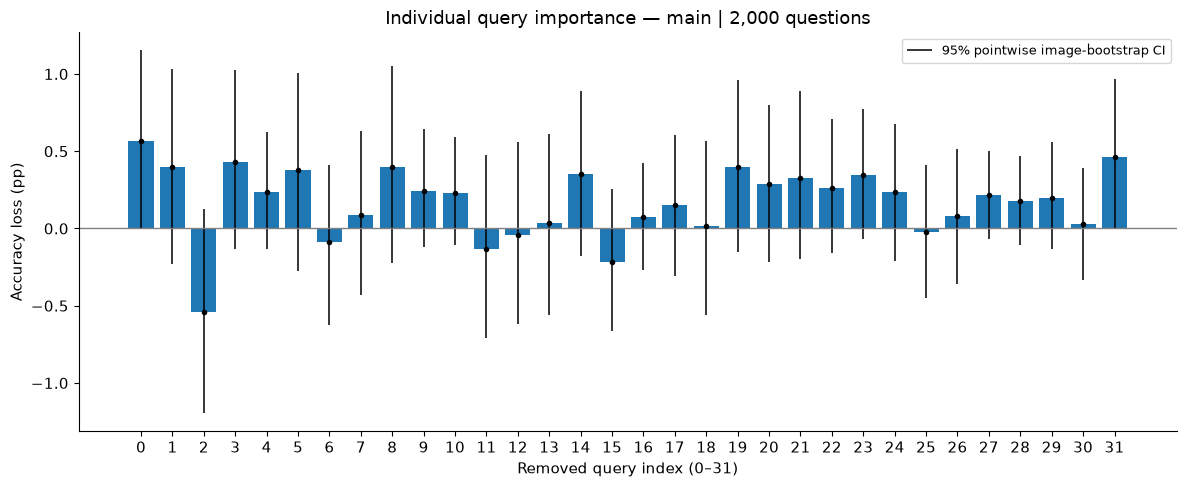

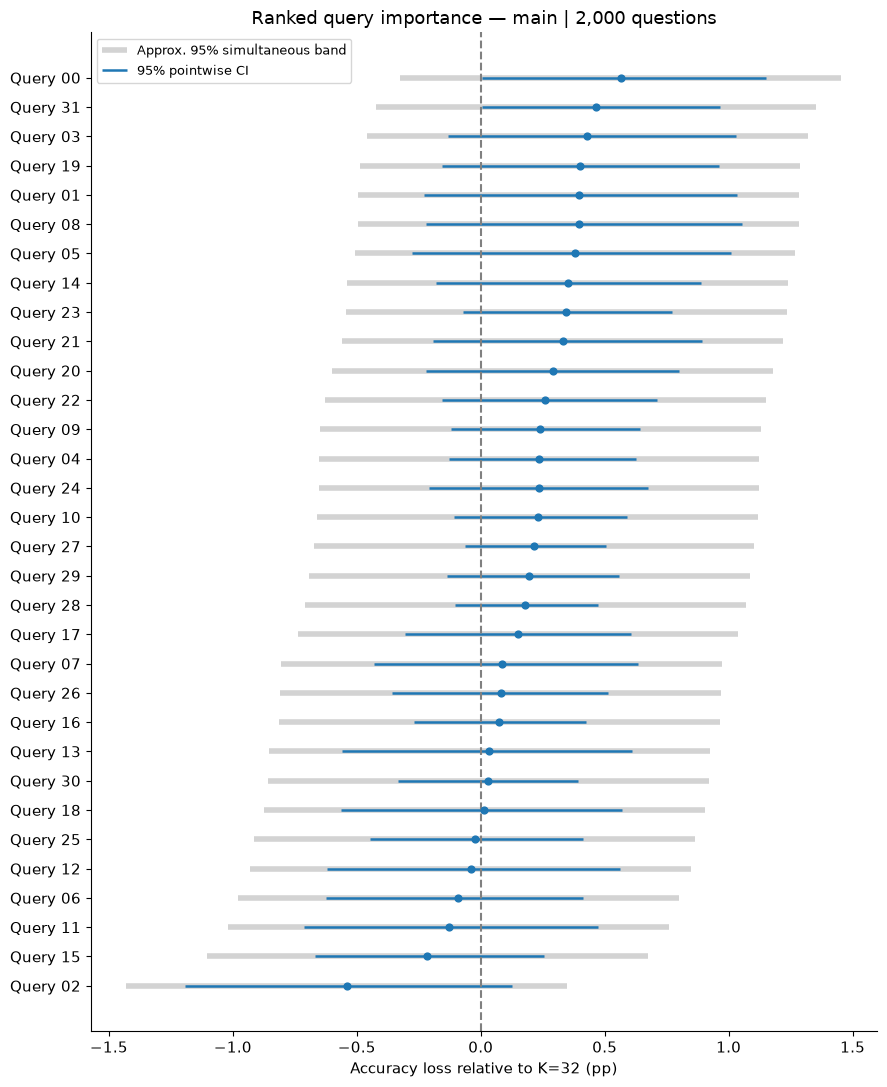

In [7]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
label = f"{STAGE} | {len(question_ids):,} questions"


def save_show(fig, filename):
    fig.tight_layout()
    fig.savefig(report_dir / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# Draw confidence intervals directly rather than assuming percentile bounds contain the estimate.
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(importance.removed_query, importance.importance_pp)
ax.vlines(importance.removed_query, importance.ci_lower_pp, importance.ci_upper_pp,
          color="black", linewidth=1.1, label="95% pointwise image-bootstrap CI")
ax.scatter(importance.removed_query, importance.importance_pp, color="black", s=9, zorder=3)
ax.axhline(0, color="gray", linewidth=1)
ax.set(xlabel="Removed query index (0–31)", ylabel="Accuracy loss (pp)",
       title=f"Individual query importance — {label}", xticks=np.arange(32))
ax.legend(fontsize=9)
save_show(fig, "query_importance.png")

fig, ax = plt.subplots(figsize=(9, 11))
y = np.arange(len(ranked))
ax.hlines(y, ranked.simultaneous_lower_pp, ranked.simultaneous_upper_pp,
          color="lightgray", linewidth=4, label="Approx. 95% simultaneous band")
ax.hlines(y, ranked.ci_lower_pp, ranked.ci_upper_pp, linewidth=1.8,
          label="95% pointwise CI")
ax.scatter(ranked.importance_pp, y, s=24, zorder=3)
ax.axvline(0, color="gray", linestyle="--")
ax.set(yticks=y, yticklabels=[f"Query {i:02d}" for i in ranked.removed_query],
       xlabel="Accuracy loss relative to K=32 (pp)", title=f"Ranked query importance — {label}")
ax.invert_yaxis()
ax.legend(fontsize=9, loc="best")
save_show(fig, "ranked_query_importance.png")

The first figure shows all 32 omissions in their original query-index order, and the second ranks them by observed marginal importance. Positive values indicate an accuracy loss after removal. Both figures display the pointwise bootstrap interval; the ranked figure additionally displays the approximate simultaneous band. A vertical or horizontal line at zero represents no accuracy difference. Smoke/pilot figures are labeled with their sample size.

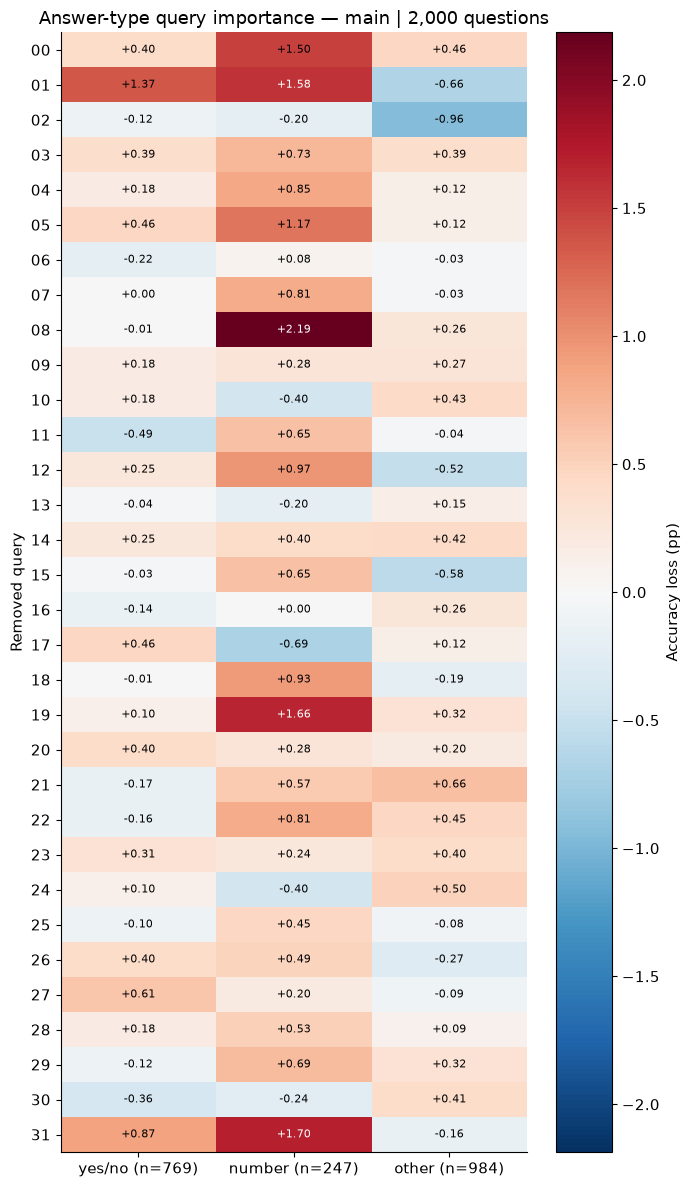

In [8]:
heat = answer_type_summary.pivot(index="removed_query", columns="answer_type", values="importance_pp").reindex(index=range(32), columns=answer_types)
counts = {a: int((question_types == a).sum()) for a in answer_types}
values = heat.to_numpy(dtype=float)
finite = values[np.isfinite(values)]
limit = max(float(np.max(np.abs(finite))) if finite.size else 0.0, 0.01)
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("lightgray")
fig, ax = plt.subplots(figsize=(7, 12))
image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, vmin=-limit, vmax=limit, aspect="auto")
ax.set(xticks=np.arange(3), xticklabels=[f"{a} (n={counts[a]})" for a in answer_types],
       yticks=np.arange(32), yticklabels=[f"{i:02d}" for i in range(32)],
       ylabel="Removed query", title=f"Answer-type query importance — {label}")
for i in range(32):
    for j in range(3):
        value = values[i, j]
        ax.text(j, i, f"{value:+.2f}" if np.isfinite(value) else "N/A",
                ha="center", va="center", fontsize=8,
                color="white" if np.isfinite(value) and abs(value) > 0.7 * limit else "black")
fig.colorbar(image, ax=ax, label="Accuracy loss (pp)")
save_show(fig, "query_importance_by_answer_type.png")

The diverging heatmap is centered at zero. Each row represents a removed query and each column an answer type. Positive values indicate that removing the query reduced the corresponding category's accuracy. Categories absent from a smoke sample are marked `N/A` and left gray. These are descriptive subgroup comparisons.

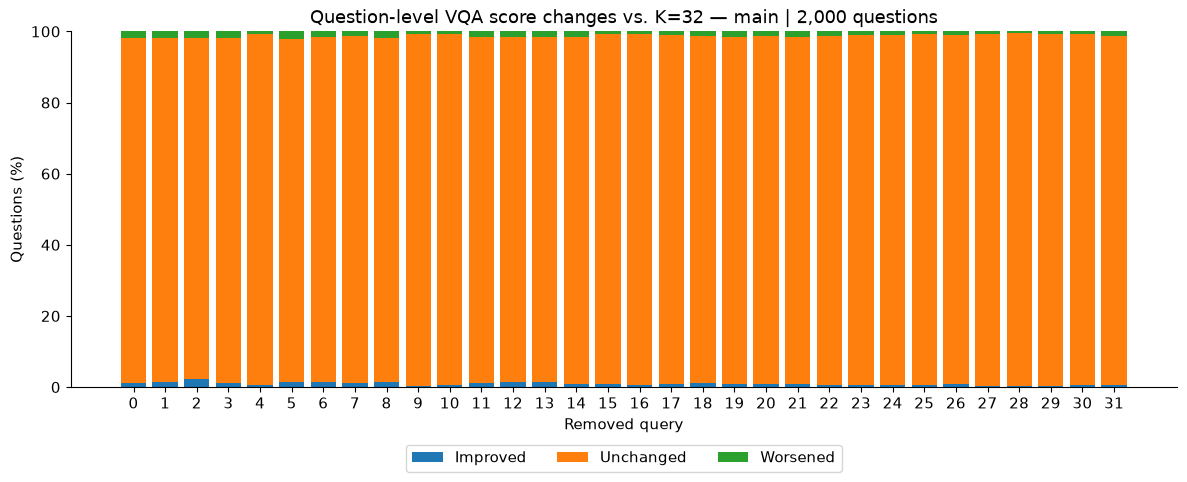

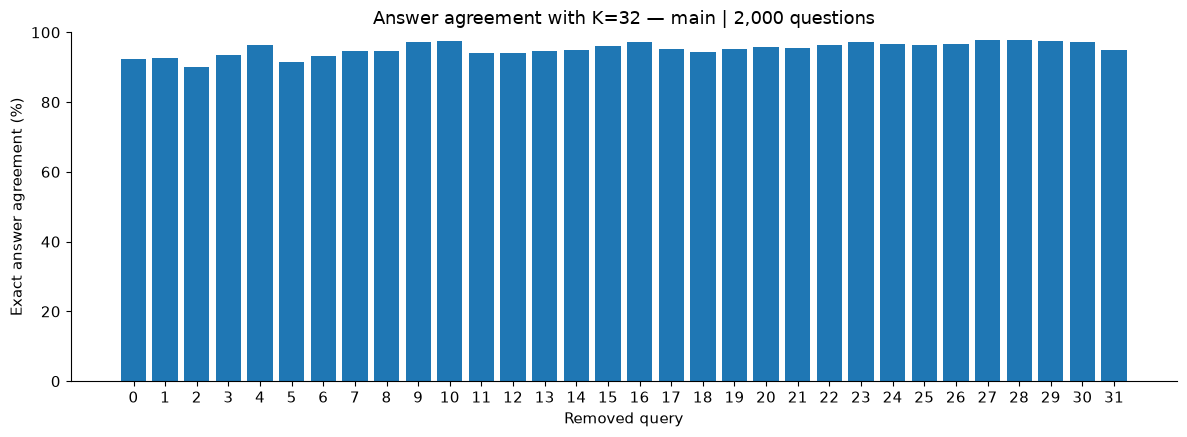

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
x = change_summary.removed_query.to_numpy()
bottom = np.zeros(len(x))
for col, title in [("improved_pct", "Improved"), ("unchanged_pct", "Unchanged"), ("worsened_pct", "Worsened")]:
    vals = change_summary[col].to_numpy()
    ax.bar(x, vals, bottom=bottom, label=title)
    bottom += vals
ax.set(xlabel="Removed query", ylabel="Questions (%)", ylim=(0, 100), xticks=np.arange(32),
       title=f"Question-level VQA score changes vs. K=32 — {label}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
save_show(fig, "question_level_changes.png")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x, change_summary.exact_answer_agreement_pct)
ax.set(xlabel="Removed query", ylabel="Exact answer agreement (%)", ylim=(0, 100),
       xticks=np.arange(32), title=f"Answer agreement with K=32 — {label}")
save_show(fig, "prediction_agreement.png")

The stacked bars describe how each omission changes official question scores. The separate agreement plot shows exact generated-answer agreement with the full model. A high agreement rate does not necessarily imply equal VQA accuracy, and vice versa.

### Overall Leave-One-Query-Out Ablation Results

The pretrained BLIP-2 Flan-T5-XL model was evaluated using leave-one-query-out ablation (LOQOA) on 2,000 VQAv2 validation questions corresponding to 1,931 unique COCO images. A total of 33 experimental conditions and 66,000 predictions were evaluated on an NVIDIA GeForce RTX 5070 Ti using CUDA.

The original $K=32$ model served as the reference configuration. Each of the remaining 32 conditions retained 31 pretrained queries while removing exactly one original query embedding before Q-Former processing.

The marginal importance of query $i$ is defined as

$$I_i = A_{32} - A_{-i},$$

where $A_{32}$ represents the original model's VQA accuracy and $A_{-i}$ represents the accuracy after removing query $i$.

A positive importance score indicates that removing the query decreased accuracy, while a negative importance score indicates that removing the query improved observed accuracy.

| Metric | Result |
|:---|---:|
| Original $K=32$ accuracy | 59.490% |
| Mean $K=31$ accuracy across all omissions | 59.316% |
| Mean marginal importance | 0.174 pp |
| Lowest observed $K=31$ accuracy | 58.925% |
| Highest observed $K=31$ accuracy | 60.030% |
| Queries with positive observed importance | 26 |
| Queries with negative observed importance | 6 |

On average, removing one pretrained query resulted in a relatively small accuracy decrease of approximately 0.174 percentage points.

These findings suggest that BLIP-2's pretrained query bottleneck exhibits substantial local robustness to individual query removal. However, the effect of removing a query varies depending on its identity.

### Individual Query Importance

The following table presents the marginal importance of all 32 pretrained queries, ranked from highest to lowest observed importance.

| Rank | Removed Query | $K=31$ Accuracy (%) | Importance (pp) |
|---:|---:|---:|---:|
| 1 | 0 | 58.925 | 0.565 |
| 2 | 31 | 59.025 | 0.465 |
| 3 | 3 | 59.060 | 0.430 |
| 4 | 19 | 59.090 | 0.400 |
| 5 | 1 | 59.095 | 0.395 |
| 5 | 8 | 59.095 | 0.395 |
| 7 | 5 | 59.110 | 0.380 |
| 8 | 14 | 59.140 | 0.350 |
| 9 | 23 | 59.145 | 0.345 |
| 10 | 21 | 59.160 | 0.330 |
| 11 | 20 | 59.200 | 0.290 |
| 12 | 22 | 59.230 | 0.260 |
| 13 | 9 | 59.250 | 0.240 |
| 14 | 4 | 59.255 | 0.235 |
| 14 | 24 | 59.255 | 0.235 |
| 16 | 10 | 59.260 | 0.230 |
| 17 | 27 | 59.275 | 0.215 |
| 18 | 29 | 59.295 | 0.195 |
| 19 | 28 | 59.310 | 0.180 |
| 20 | 17 | 59.340 | 0.150 |
| 21 | 7 | 59.405 | 0.085 |
| 22 | 26 | 59.410 | 0.080 |
| 23 | 16 | 59.415 | 0.075 |
| 24 | 13 | 59.455 | 0.035 |
| 25 | 30 | 59.460 | 0.030 |
| 26 | 18 | 59.475 | 0.015 |
| 27 | 25 | 59.515 | -0.025 |
| 28 | 12 | 59.530 | -0.040 |
| 29 | 6 | 59.580 | -0.090 |
| 30 | 11 | 59.620 | -0.130 |
| 31 | 15 | 59.705 | -0.215 |
| 32 | 2 | 60.030 | -0.540 |

Query indices are zero-based, corresponding to the original 32 pretrained Q-Former embeddings. Tied importance values share the same rank.

Query 0 exhibited the largest positive marginal importance. Removing it reduced VQA accuracy from 59.490% to 58.925%, corresponding to a decrease of 0.565 percentage points.

Queries 31, 3, and 19 also exhibited relatively large positive observed importance values.

In contrast, removing queries 2, 15, 11, 6, 12, and 25 improved observed accuracy relative to the original model.

The largest improvement occurred when removing query 2, resulting in an accuracy of 60.030%, an increase of 0.540 percentage points over the original model.

The difference between the best- and worst-performing omission configurations was 1.105 percentage points. This demonstrates that individual query removals do not have identical observed effects, even though every ablation retains the same number of queries.

### Statistical Significance and Bootstrap Confidence Intervals

Paired image-cluster bootstrap confidence intervals were calculated using 2,000 bootstrap replicates. Resampling was performed at the image level to account for potential dependence between questions associated with the same COCO image.

Because all 33 conditions were evaluated on identical questions, the bootstrap procedure preserves the paired experimental structure.

Selected confidence intervals are presented below.

| Removed Query | Importance (pp) | Pointwise 95% CI (pp) | Approximate Simultaneous 95% CI (pp) |
|---:|---:|:---|:---|
| 0 | 0.565 | [0.0050, 1.1525] | [-0.3241, 1.4541] |
| 31 | 0.465 | [0.0049, 0.9660] | [-0.4241, 1.3541] |
| 3 | 0.430 | [-0.1307, 1.0276] | [-0.4591, 1.3191] |
| 19 | 0.400 | [-0.1548, 0.9605] | [-0.4891, 1.2891] |
| 1 | 0.395 | [-0.2308, 1.0326] | [-0.4941, 1.2841] |
| 15 | -0.215 | [-0.6667, 0.2564] | [-1.1041, 0.6741] |
| 2 | -0.540 | [-1.1945, 0.1246] | [-1.4291, 0.3491] |

Queries 0 and 31 were the only queries whose individual 95% bootstrap confidence intervals excluded zero. However, their lower confidence bounds were extremely close to zero, suggesting that the evidence for positive marginal importance is relatively weak.

Furthermore, evaluating 32 individual queries introduces a multiple-comparison problem. When applying the approximate simultaneous confidence band based on the maximum absolute centered bootstrap deviation, every query's interval included zero.

Consequently, none of the individual query importance estimates can be distinguished from zero using the approximate simultaneous 95% confidence band.

Although removing query 2 improved observed accuracy, its pointwise and simultaneous confidence intervals both included zero. Therefore, the experiment does not establish that removing query 2 reliably improves generalization performance.

The ranked importance values should be interpreted as exploratory estimates rather than definitive statistical evidence that particular queries are more important than others.

### Query Redundancy and Local Robustness

The original query-count experiment demonstrated substantial accuracy reductions when removing multiple pretrained queries simultaneously.

| Query Configuration | Mean VQA Accuracy (%) | Accuracy Difference from $K=32$ (pp) |
|:---|---:|---:|
| $K=8$ random pruning | 53.325 | -6.165 |
| $K=16$ random pruning | 56.359 | -3.131 |
| $K=31$ individual query removal | 59.316 | -0.174 |
| $K=32$ original baseline | 59.490 | 0.000 |

The relatively small marginal effect of individual query removal contrasts with the larger accuracy reductions observed when many queries were removed simultaneously.

These findings are consistent with the possibility that pretrained queries contain overlapping or redundant visual information. When one query is removed, the remaining 31 queries may retain much of the information necessary for downstream question answering.

However, simultaneously removing multiple queries may eliminate complementary information or disrupt interactions between the remaining query embeddings.

Importantly, individual query importance values are not necessarily additive. The combined effect of removing multiple queries cannot be reliably determined by summing their individual leave-one-out importance scores.

Therefore, the most influential individual queries identified through LOQOA are not necessarily the optimal subset for a heavily compressed Q-Former.

### Query Importance by Answer Type

Individual query importance was also evaluated separately across the three official VQAv2 answer categories: yes/no, number, and other.

The following table presents selected queries that exhibited relatively large or contrasting category-level importance values.

| Removed Query | Yes/No Importance (pp) | Number Importance (pp) | Other Importance (pp) |
|---:|---:|---:|---:|
| 0 | 0.403 | 1.498 | 0.457 |
| 1 | 1.365 | 1.579 | -0.661 |
| 2 | -0.117 | -0.202 | -0.955 |
| 3 | 0.390 | 0.729 | 0.386 |
| 5 | 0.455 | 1.174 | 0.122 |
| 8 | -0.013 | 2.186 | 0.264 |
| 19 | 0.104 | 1.660 | 0.315 |
| 21 | -0.169 | 0.567 | 0.661 |
| 31 | 0.871 | 1.700 | -0.163 |

The results indicate that individual query removals can have different effects across answer categories.

Query 8 exhibited the largest positive marginal importance for numerical questions. Removing this query decreased numerical accuracy by 2.186 percentage points, while having comparatively little effect on yes/no and other questions.

Query 1 exhibited the largest positive marginal importance for yes/no questions, with a decrease of 1.365 percentage points after removal. However, removing query 1 improved accuracy in the other category by 0.661 percentage points.

Query 21 exhibited the largest positive observed importance for questions in the other category, with an accuracy decrease of 0.661 percentage points.

Removing query 2 improved observed accuracy across all three answer categories, with the largest improvement occurring in the other category.

Queries 0, 3, 5, and 19 exhibited positive observed importance across all three categories, indicating that their removal consistently decreased category-level accuracy on the evaluated sample.

These findings suggest the possibility of differences in the information represented by individual pretrained queries. Some queries may contribute more strongly to particular visual reasoning tasks than others.

However, these category-level comparisons are descriptive. The categories have different sample sizes, no category-level confidence intervals were calculated, and the analysis includes many simultaneous comparisons.

Therefore, the results do not establish that individual queries are specifically specialized for counting, object recognition, or other visual reasoning tasks.

### Question-Level Performance Changes

Each leave-one-query-out condition was also compared with the original $K=32$ configuration using official question-level VQA scores and exact generated-answer agreement.

| Removed Query | Improved (%) | Unchanged (%) | Worsened (%) | Exact Answer Agreement (%) |
|---:|---:|---:|---:|---:|
| 0 | 1.05 | 97.15 | 1.80 | 92.40 |
| 1 | 1.35 | 96.70 | 1.95 | 92.60 |
| 2 | 2.30 | 95.85 | 1.85 | 90.00 |
| 3 | 1.05 | 97.15 | 1.80 | 93.45 |
| 5 | 1.40 | 96.40 | 2.20 | 91.40 |
| 8 | 1.35 | 96.80 | 1.85 | 94.55 |
| 15 | 0.90 | 98.30 | 0.80 | 96.20 |
| 19 | 1.00 | 97.50 | 1.50 | 95.30 |
| 28 | 0.20 | 99.25 | 0.55 | 97.90 |
| 31 | 0.70 | 97.90 | 1.40 | 95.00 |

Across all 32 omissions, the percentage of questions receiving unchanged official VQA scores ranged from 95.85% to 99.25%.

This indicates that individual query removal leaves the official VQA scores of the overwhelming majority of questions unchanged.

Nevertheless, exact generated-answer agreement ranged from 90.00% to 97.90%, demonstrating that removing a single query can change the generated answer without necessarily changing its official VQA score.

Removing query 2 produced the largest proportion of improved question-level scores, at 2.30%, and the lowest exact generated-answer agreement, at 90.00%.

Removing query 5 produced the largest proportion of worsened question-level scores, at 2.20%. However, query 0 exhibited the largest overall accuracy reduction, demonstrating that the frequency of score changes alone does not determine the magnitude of an accuracy difference.

Removing query 28 produced the highest question-level score stability and exact generated-answer agreement. Nevertheless, its marginal importance remained positive at 0.180 percentage points.

These findings suggest that different pretrained queries influence both the generated answer and its correctness to varying degrees.

Exact answer agreement should not be interpreted as semantic equivalence or VQA accuracy, since different generated answers may receive identical official evaluation scores.

### Relationship to the Original Query-Count Ablation

The original query-count experiment demonstrated that the identity of retained queries can substantially affect zero-shot VQA accuracy.

In particular, one $K=16$ subset achieved 59.145% accuracy, nearly matching the original $K=32$ baseline of 59.490%, while another $K=16$ subset achieved only 50.445%.

The LOQOA results provide a complementary perspective on this observation by measuring individual query contributions while keeping the other 31 queries unchanged.

Although the individual marginal importance estimates were generally small, the results reveal variation across query identities and answer categories.

This suggests that the substantial performance variability observed in the original pruning experiment may involve higher-order interactions and redundancy among pretrained queries, rather than being explained exclusively by individual query importance.

The absence of statistically distinguishable individual importance estimates after accounting for multiple comparisons does not contradict the significant accuracy reductions observed when removing many queries simultaneously.

Instead, the two experiments investigate different aspects of the pretrained visual information bottleneck:

- Query-count ablation measures the effect of reducing the number of available queries across different subsets.
- Leave-one-query-out ablation measures the marginal effect of removing one query while retaining all other pretrained queries.

Together, these experiments motivate investigating both individual query contributions and interactions among groups of queries.

### Limitations

Several limitations should be considered when interpreting the LOQOA results.

First, individual marginal importance is conditional on the presence of the remaining 31 pretrained queries. A query exhibiting low marginal importance may still become important when other queries are removed.

Second, the query importance rankings were calculated using the same 2,000-question evaluation sample. Selecting a new query subset based on these results and evaluating it on the same sample may produce an optimistically biased estimate of generalization performance.

Third, all simultaneous confidence intervals included zero. Consequently, the observed ranking should not be treated as definitive evidence of statistically distinguishable individual query contributions.

Fourth, the answer-type results are descriptive and do not establish functional specialization of individual queries. Additional attention analysis, representation analysis, or controlled visual reasoning experiments would be required to investigate specialization more directly.

Finally, the experiment evaluates inference-time removal of pretrained embeddings rather than independently trained Q-Former architectures. It therefore characterizes the local sensitivity of the existing pretrained model, rather than determining the optimal learned query configuration.

### Future Work: Importance-Based Query Selection

A natural extension of this experiment is to investigate whether the observed LOQOA importance ranking can guide more effective query pruning.

Based on the estimated importance scores, candidate importance-based subsets can be constructed by retaining the highest-ranked pretrained queries.

For example, the eight highest-ranked queries are

$$Q_8 = \{0,1,3,5,8,14,19,31\}.$$

The sixteen highest-ranked queries are

$$Q_{16} = \{0,1,3,4,5,8,9,10,14,19,20,21,22,23,24,31\}.$$

The selected query embeddings should retain their original index order when supplied to the Q-Former.

These importance-based subsets could be compared against the five random pruning subsets already evaluated for $K=8$ and $K=16$.

Additional comparison conditions could include the lowest-ranked query subsets and random subsets evaluated under identical generation settings.

Importantly, these proposed subsets are exploratory candidates rather than proven optimal configurations. Their performance must be evaluated empirically, preferably on an independent validation sample that was not used to estimate the LOQOA rankings.

Such an experiment would investigate whether individual marginal importance provides useful information for selecting a compressed visual bottleneck, despite potential interactions and redundancy among queries.

### Conclusion

The leave-one-query-out ablation experiment evaluated all 32 pretrained Q-Former queries individually across 2,000 VQAv2 validation questions.

The original BLIP-2 model achieved an accuracy of 59.490%, while the 32 individual query-removal configurations achieved a mean accuracy of 59.316%.

Most individual query removals produced relatively small accuracy reductions, indicating that the pretrained visual bottleneck is locally robust to removing a single query.

Query 0 exhibited the largest positive observed marginal importance, while removing query 2 produced the largest observed accuracy improvement. However, none of the individual importance estimates remained statistically distinguishable from zero under the approximate simultaneous confidence band.

The answer-type and question-level analyses revealed differences in how individual query removals affect downstream predictions, motivating further investigation into query specialization, redundancy, and interactions.

Combined with the original query-count ablation, these findings suggest that effective query compression may depend on selecting complementary groups of pretrained queries rather than simply retaining queries with the largest individual marginal importance.

Overall, the LOQOA experiment provides an exploratory foundation for developing and evaluating importance-based query pruning strategies in pretrained multimodal models.